<a href="https://colab.research.google.com/github/JuanitaRozo/Practica-GAN-MNIST/blob/main/Practica_GAN_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import time

from tensorflow.keras import layers
from IPython.display import display

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPU disponible: []


In [ ]:


# Cargar el conjunto de datos MNIST
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalizar las imágenes entre -1 y 1
x_train = (x_train.astype("float32") - 127.5) / 127.5

# Agregar dimensión del canal
x_train = np.expand_dims(x_train, axis=-1)

print("Dimensiones del conjunto:", x_train.shape)
print("Cantidad de imágenes:", len(x_train))
print("Tamaño de cada imagen:", x_train.shape[1:3])


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensiones del conjunto: (60000, 28, 28, 1)
Cantidad de imágenes: 60000
Tamaño de cada imagen: (28, 28)


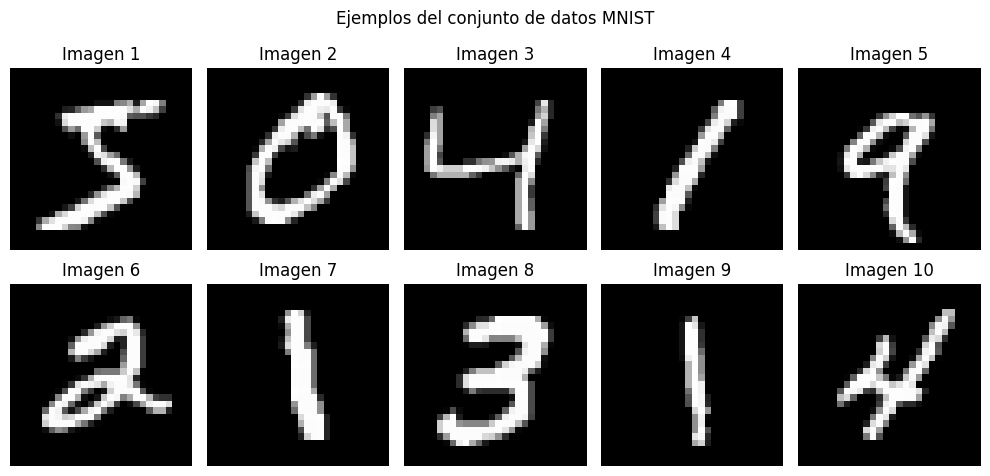

In [ ]:

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.axis("off")
    plt.title(f"Imagen {i+1}")

plt.suptitle("Ejemplos del conjunto de datos MNIST")
plt.tight_layout()
plt.show()


In [ ]:

BUFFER_SIZE = 60000
BATCH_SIZE = 256

dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Datos preparados correctamente.")


Datos preparados correctamente.


In [ ]:

def crear_generador():

    modelo = tf.keras.Sequential([
        layers.Input(shape=(100,)),

        layers.Dense(7 * 7 * 128, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 128)),

        layers.Conv2DTranspose(
            64, 5, strides=2,
            padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(
            1, 5, strides=2,
            padding="same", activation="tanh"
        )
    ], name="Generador")

    return modelo


generador = crear_generador()
generador.summary()


Model: "Generador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 858,945 (3.28 MB)

 Trainable params: 846,273 (3.23 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [ ]:

def crear_discriminador():

    modelo = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(
            64, 5, strides=2, padding="same"
        ),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(
            128, 5, strides=2, padding="same"
        ),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ], name="Discriminador")

    return modelo


discriminador = crear_discriminador()
discriminador.summary()


Model: "Discriminador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

ruido = tf.random.normal([1, 100])

imagen_generada = generador(ruido, training=False)

resultado = discriminador(imagen_generada, training=False)

print("Dimensiones de imagen generada:",
      imagen_generada.shape)

print("Resultado del discriminador:",
      resultado.numpy())


Dimensiones de imagen generada: (1, 28, 28, 1)
Resultado del discriminador: [[-0.00020568]]


In [ ]:

funcion_perdida = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

def perdida_generador(salida_falsa):
    return funcion_perdida(
        tf.ones_like(salida_falsa),
        salida_falsa
    )

def perdida_discriminador(salida_real, salida_falsa):

    perdida_real = funcion_perdida(
        tf.ones_like(salida_real),
        salida_real
    )

    perdida_falsa = funcion_perdida(
        tf.zeros_like(salida_falsa),
        salida_falsa
    )

    return perdida_real + perdida_falsa


optimizador_generador = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

optimizador_discriminador = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

print("Funciones de pérdida y optimizadores configurados.")


Funciones de pérdida y optimizadores configurados.


In [ ]:

RUIDO_DIMENSION = 100
EPOCHS = 50
NUM_EJEMPLOS = 16

semillas = tf.random.normal(
    [NUM_EJEMPLOS, RUIDO_DIMENSION]
)

historial_generador = []
historial_discriminador = []

os.makedirs("resultados_gan", exist_ok=True)

@tf.function
def paso_entrenamiento(imagenes_reales):

    ruido = tf.random.normal(
        [BATCH_SIZE, RUIDO_DIMENSION]
    )

    with tf.GradientTape() as cinta_g, \
         tf.GradientTape() as cinta_d:

        imagenes_falsas = generador(ruido, training=True)

        salida_real = discriminador(
            imagenes_reales, training=True
        )

        salida_falsa = discriminador(
            imagenes_falsas, training=True
        )

        perdida_g = perdida_generador(salida_falsa)

        perdida_d = perdida_discriminador(
            salida_real, salida_falsa
        )

    gradientes_g = cinta_g.gradient(
        perdida_g, generador.trainable_variables
    )

    gradientes_d = cinta_d.gradient(
        perdida_d, discriminador.trainable_variables
    )

    optimizador_generador.apply_gradients(
        zip(gradientes_g, generador.trainable_variables)
    )

    optimizador_discriminador.apply_gradients(
        zip(gradientes_d, discriminador.trainable_variables)
    )

    return perdida_g, perdida_d


In [ ]:

def generar_y_guardar_imagenes(epoca):

    predicciones = generador(
        semillas, training=False
    )

    fig = plt.figure(figsize=(6, 6))

    for i in range(predicciones.shape[0]):
        plt.subplot(4, 4, i + 1)

        imagen = (predicciones[i, :, :, 0] + 1) / 2

        plt.imshow(imagen, cmap="gray")
        plt.axis("off")

    plt.suptitle(f"Imágenes generadas - Época {epoca}")
    plt.tight_layout()

    ruta = f"resultados_gan/epoca_{epoca:03d}.png"

    plt.savefig(ruta)
    plt.show()
    plt.close()

    return ruta


entrenar la red gran

Época 1/50 | Generador: 0.8106 | Discriminador: 1.0995


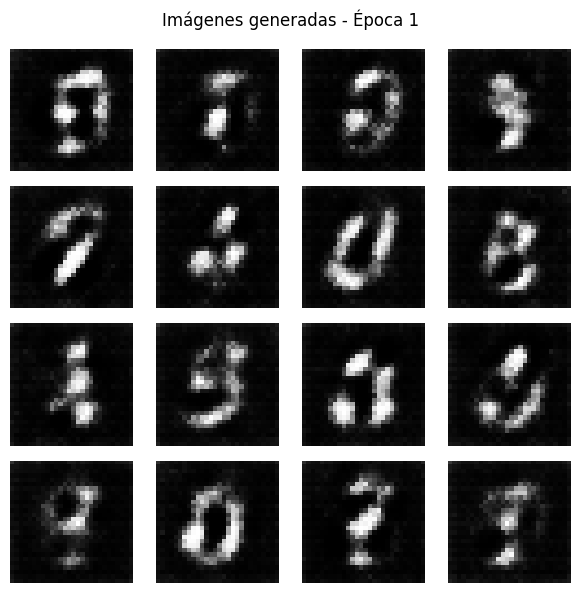

Época 2/50 | Generador: 0.7676 | Discriminador: 1.3225
Época 3/50 | Generador: 0.7661 | Discriminador: 1.3209
Época 4/50 | Generador: 0.7966 | Discriminador: 1.2883
Época 5/50 | Generador: 0.8529 | Discriminador: 1.2364


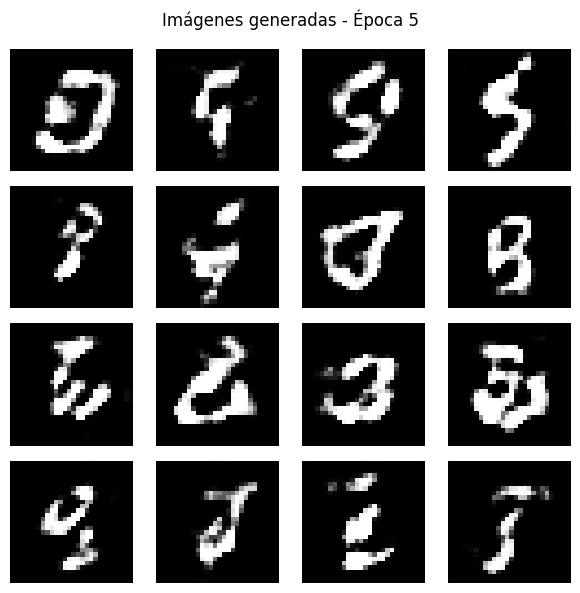

Época 6/50 | Generador: 0.9194 | Discriminador: 1.1819
Época 7/50 | Generador: 0.9760 | Discriminador: 1.1517
Época 8/50 | Generador: 0.9478 | Discriminador: 1.1783
Época 9/50 | Generador: 0.9438 | Discriminador: 1.2122
Época 10/50 | Generador: 0.9165 | Discriminador: 1.2281


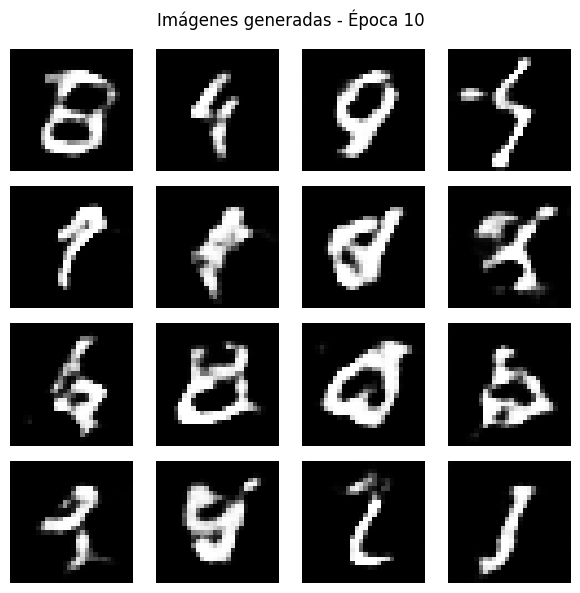

Época 11/50 | Generador: 0.9111 | Discriminador: 1.2337
Época 12/50 | Generador: 0.8925 | Discriminador: 1.2400
Época 13/50 | Generador: 0.8877 | Discriminador: 1.2456
Época 14/50 | Generador: 0.8752 | Discriminador: 1.2549
Época 15/50 | Generador: 0.8867 | Discriminador: 1.2511


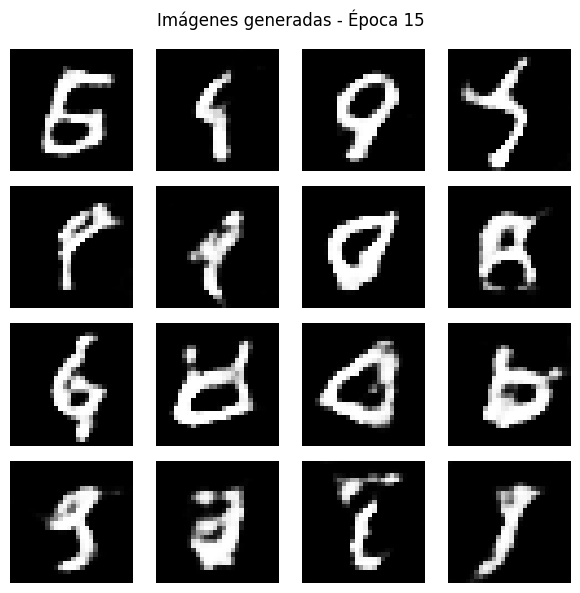

Época 16/50 | Generador: 0.8814 | Discriminador: 1.2521
Época 17/50 | Generador: 0.8737 | Discriminador: 1.2546
Época 18/50 | Generador: 0.8809 | Discriminador: 1.2542
Época 19/50 | Generador: 0.8898 | Discriminador: 1.2534
Época 20/50 | Generador: 0.8916 | Discriminador: 1.2484


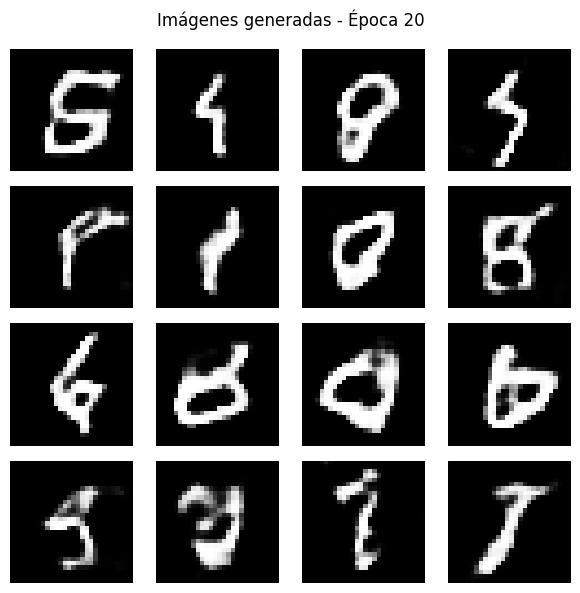

Época 21/50 | Generador: 0.8846 | Discriminador: 1.2461
Época 22/50 | Generador: 0.8915 | Discriminador: 1.2459
Época 23/50 | Generador: 0.8905 | Discriminador: 1.2429
Época 24/50 | Generador: 0.8976 | Discriminador: 1.2382
Época 25/50 | Generador: 0.9024 | Discriminador: 1.2338


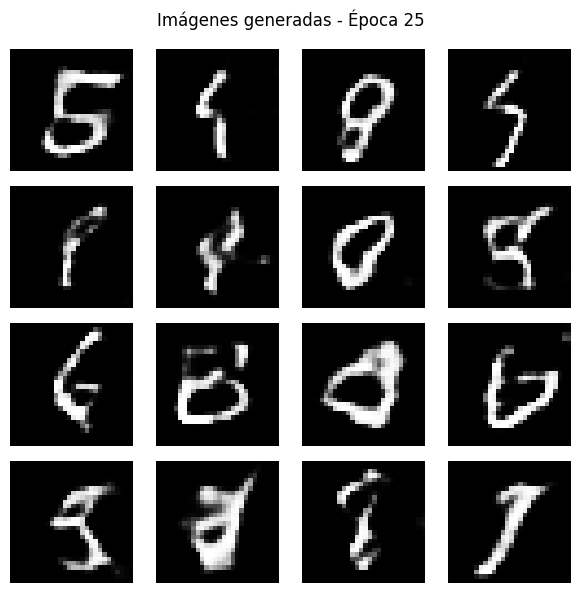

Época 26/50 | Generador: 0.9462 | Discriminador: 1.2317
Época 27/50 | Generador: 0.9045 | Discriminador: 1.2301
Época 28/50 | Generador: 0.9001 | Discriminador: 1.2335
Época 29/50 | Generador: 0.9124 | Discriminador: 1.2332
Época 30/50 | Generador: 0.9212 | Discriminador: 1.2249


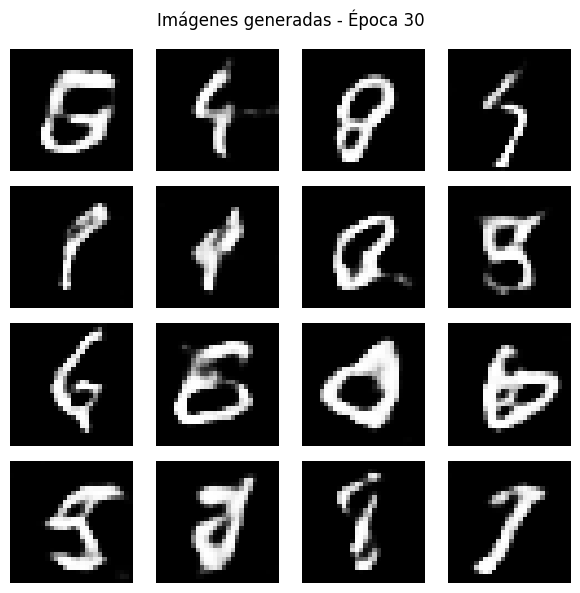

Época 31/50 | Generador: 0.9217 | Discriminador: 1.2264
Época 32/50 | Generador: 0.9321 | Discriminador: 1.2254
Época 33/50 | Generador: 0.9207 | Discriminador: 1.2276
Época 34/50 | Generador: 0.9314 | Discriminador: 1.2296
Época 35/50 | Generador: 0.9260 | Discriminador: 1.2270


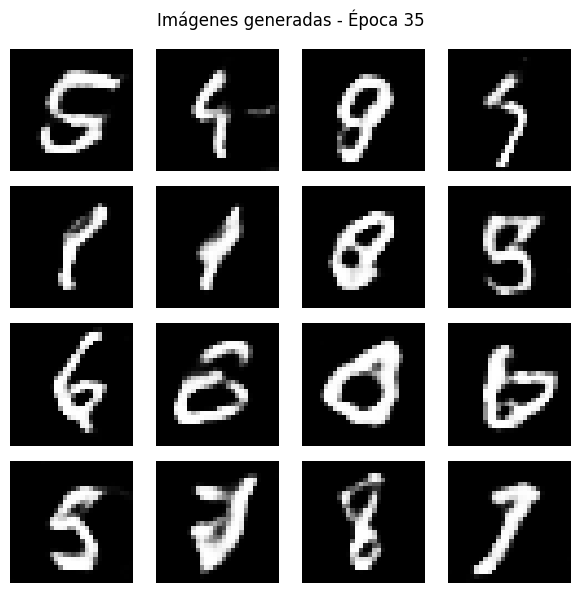

Época 36/50 | Generador: 0.9276 | Discriminador: 1.2268
Época 37/50 | Generador: 0.9291 | Discriminador: 1.2285
Época 38/50 | Generador: 0.9277 | Discriminador: 1.2280
Época 39/50 | Generador: 0.9362 | Discriminador: 1.2243
Época 40/50 | Generador: 0.9303 | Discriminador: 1.2250


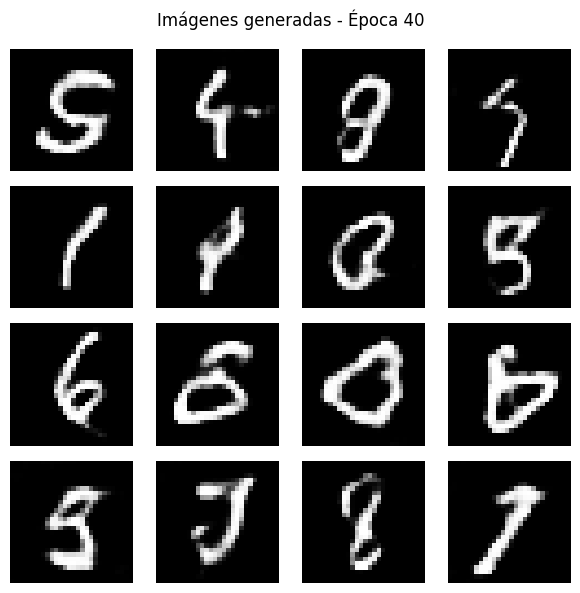

Época 41/50 | Generador: 0.9350 | Discriminador: 1.2272
Época 42/50 | Generador: 0.9301 | Discriminador: 1.2262
Época 43/50 | Generador: 0.9353 | Discriminador: 1.2256
Época 44/50 | Generador: 0.9304 | Discriminador: 1.2277
Época 45/50 | Generador: 0.9327 | Discriminador: 1.2263


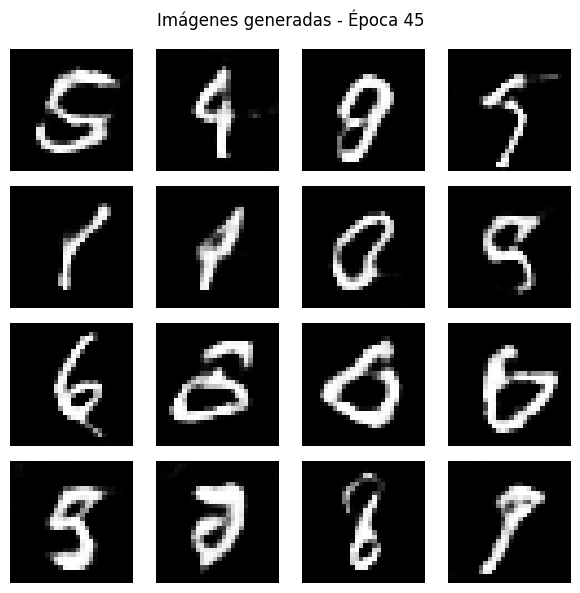

Época 46/50 | Generador: 0.9331 | Discriminador: 1.2280
Época 47/50 | Generador: 0.9370 | Discriminador: 1.2336
Época 48/50 | Generador: 0.9270 | Discriminador: 1.2304
Época 49/50 | Generador: 0.9283 | Discriminador: 1.2306
Época 50/50 | Generador: 0.9277 | Discriminador: 1.2295


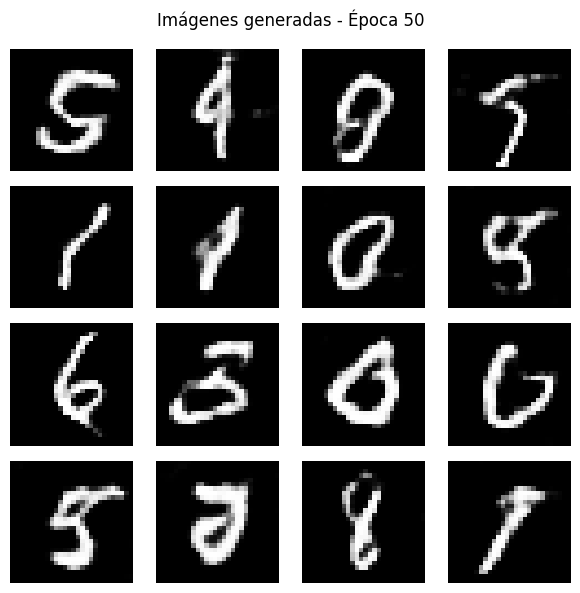


Entrenamiento finalizado.
Tiempo total: 285.57 minutos


In [ ]:

def entrenar_gan(dataset, epochs):

    inicio = time.time()

    for epoca in range(1, epochs + 1):

        perdida_g_epoca = []
        perdida_d_epoca = []

        for imagenes_reales in dataset:

            perdida_g, perdida_d = paso_entrenamiento(
                imagenes_reales
            )

            perdida_g_epoca.append(float(perdida_g.numpy()))
            perdida_d_epoca.append(float(perdida_d.numpy()))

        promedio_g = np.mean(perdida_g_epoca)
        promedio_d = np.mean(perdida_d_epoca)

        historial_generador.append(promedio_g)
        historial_discriminador.append(promedio_d)

        print(
            f"Época {epoca}/{epochs} | "
            f"Generador: {promedio_g:.4f} | "
            f"Discriminador: {promedio_d:.4f}"
        )

        if epoca == 1 or epoca % 5 == 0:
            generar_y_guardar_imagenes(epoca)

    print("\nEntrenamiento finalizado.")
    print(f"Tiempo total: {(time.time()-inicio)/60:.2f} minutos")


entrenar_gan(dataset, EPOCHS)


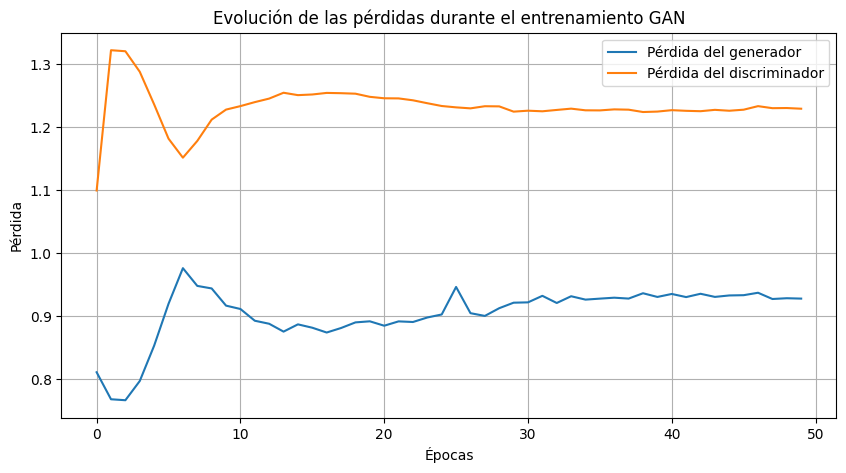

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    historial_generador,
    label="Pérdida del generador"
)

plt.plot(
    historial_discriminador,
    label="Pérdida del discriminador"
)

plt.title("Evolución de las pérdidas durante el entrenamiento GAN")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.savefig("resultados_gan/grafica_perdidas.png")
plt.show()


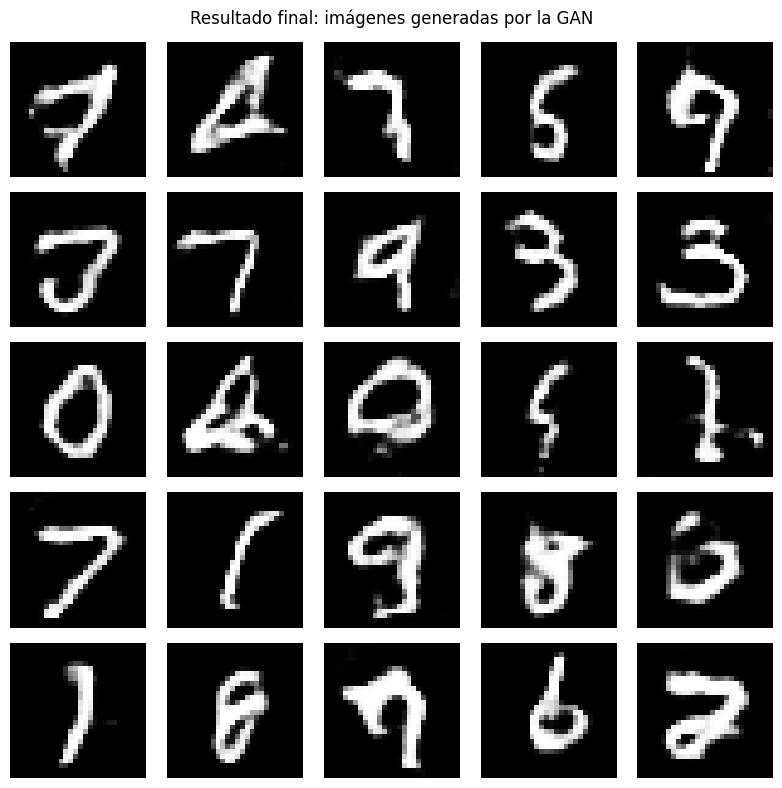

In [ ]:

ruido_final = tf.random.normal([25, 100])

imagenes_finales = generador(
    ruido_final, training=False
)

plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)

    imagen = (imagenes_finales[i, :, :, 0] + 1) / 2

    plt.imshow(imagen, cmap="gray")
    plt.axis("off")

plt.suptitle("Resultado final: imágenes generadas por la GAN")
plt.tight_layout()

plt.savefig("resultados_gan/imagenes_finales.png")
plt.show()


In [ ]:

generador.save("resultados_gan/generador.keras")
discriminador.save("resultados_gan/discriminador.keras")

print("Modelos guardados correctamente.")


Modelos guardados correctamente.


In [ ]:

import shutil
from google.colab import files

shutil.make_archive(
    "resultados_gan",
    "zip",
    "resultados_gan"
)

files.download("resultados_gan.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>